# Dataset description
## Oil daily production per month

**Source**: [Agencia Nacional de Hidrocarburos](https://www.anh.gov.co/es/operaciones-y-regal%C3%ADas/sistemas-integrados-operaciones/estad%C3%ADsticas-de-producci%C3%B3n/
)
# Code
## Imports

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [19]:
path = "./data/totales_mensuales.csv"

df = pd.read_csv(path, encoding="utf-8", parse_dates=["date"], date_format="%Y-%m-%d")

## Clean data

In [20]:
idx_max = df["total_bpdc"].idxmax()
max = df.iloc[idx_max]

avg_2019 = df[df["date"].dt.year.eq(2019)]["total_bpdc"].mean()
trough = df[df["date"].eq("2020-05-01")].iloc[0]
last = df.iloc[-1]

## Plot

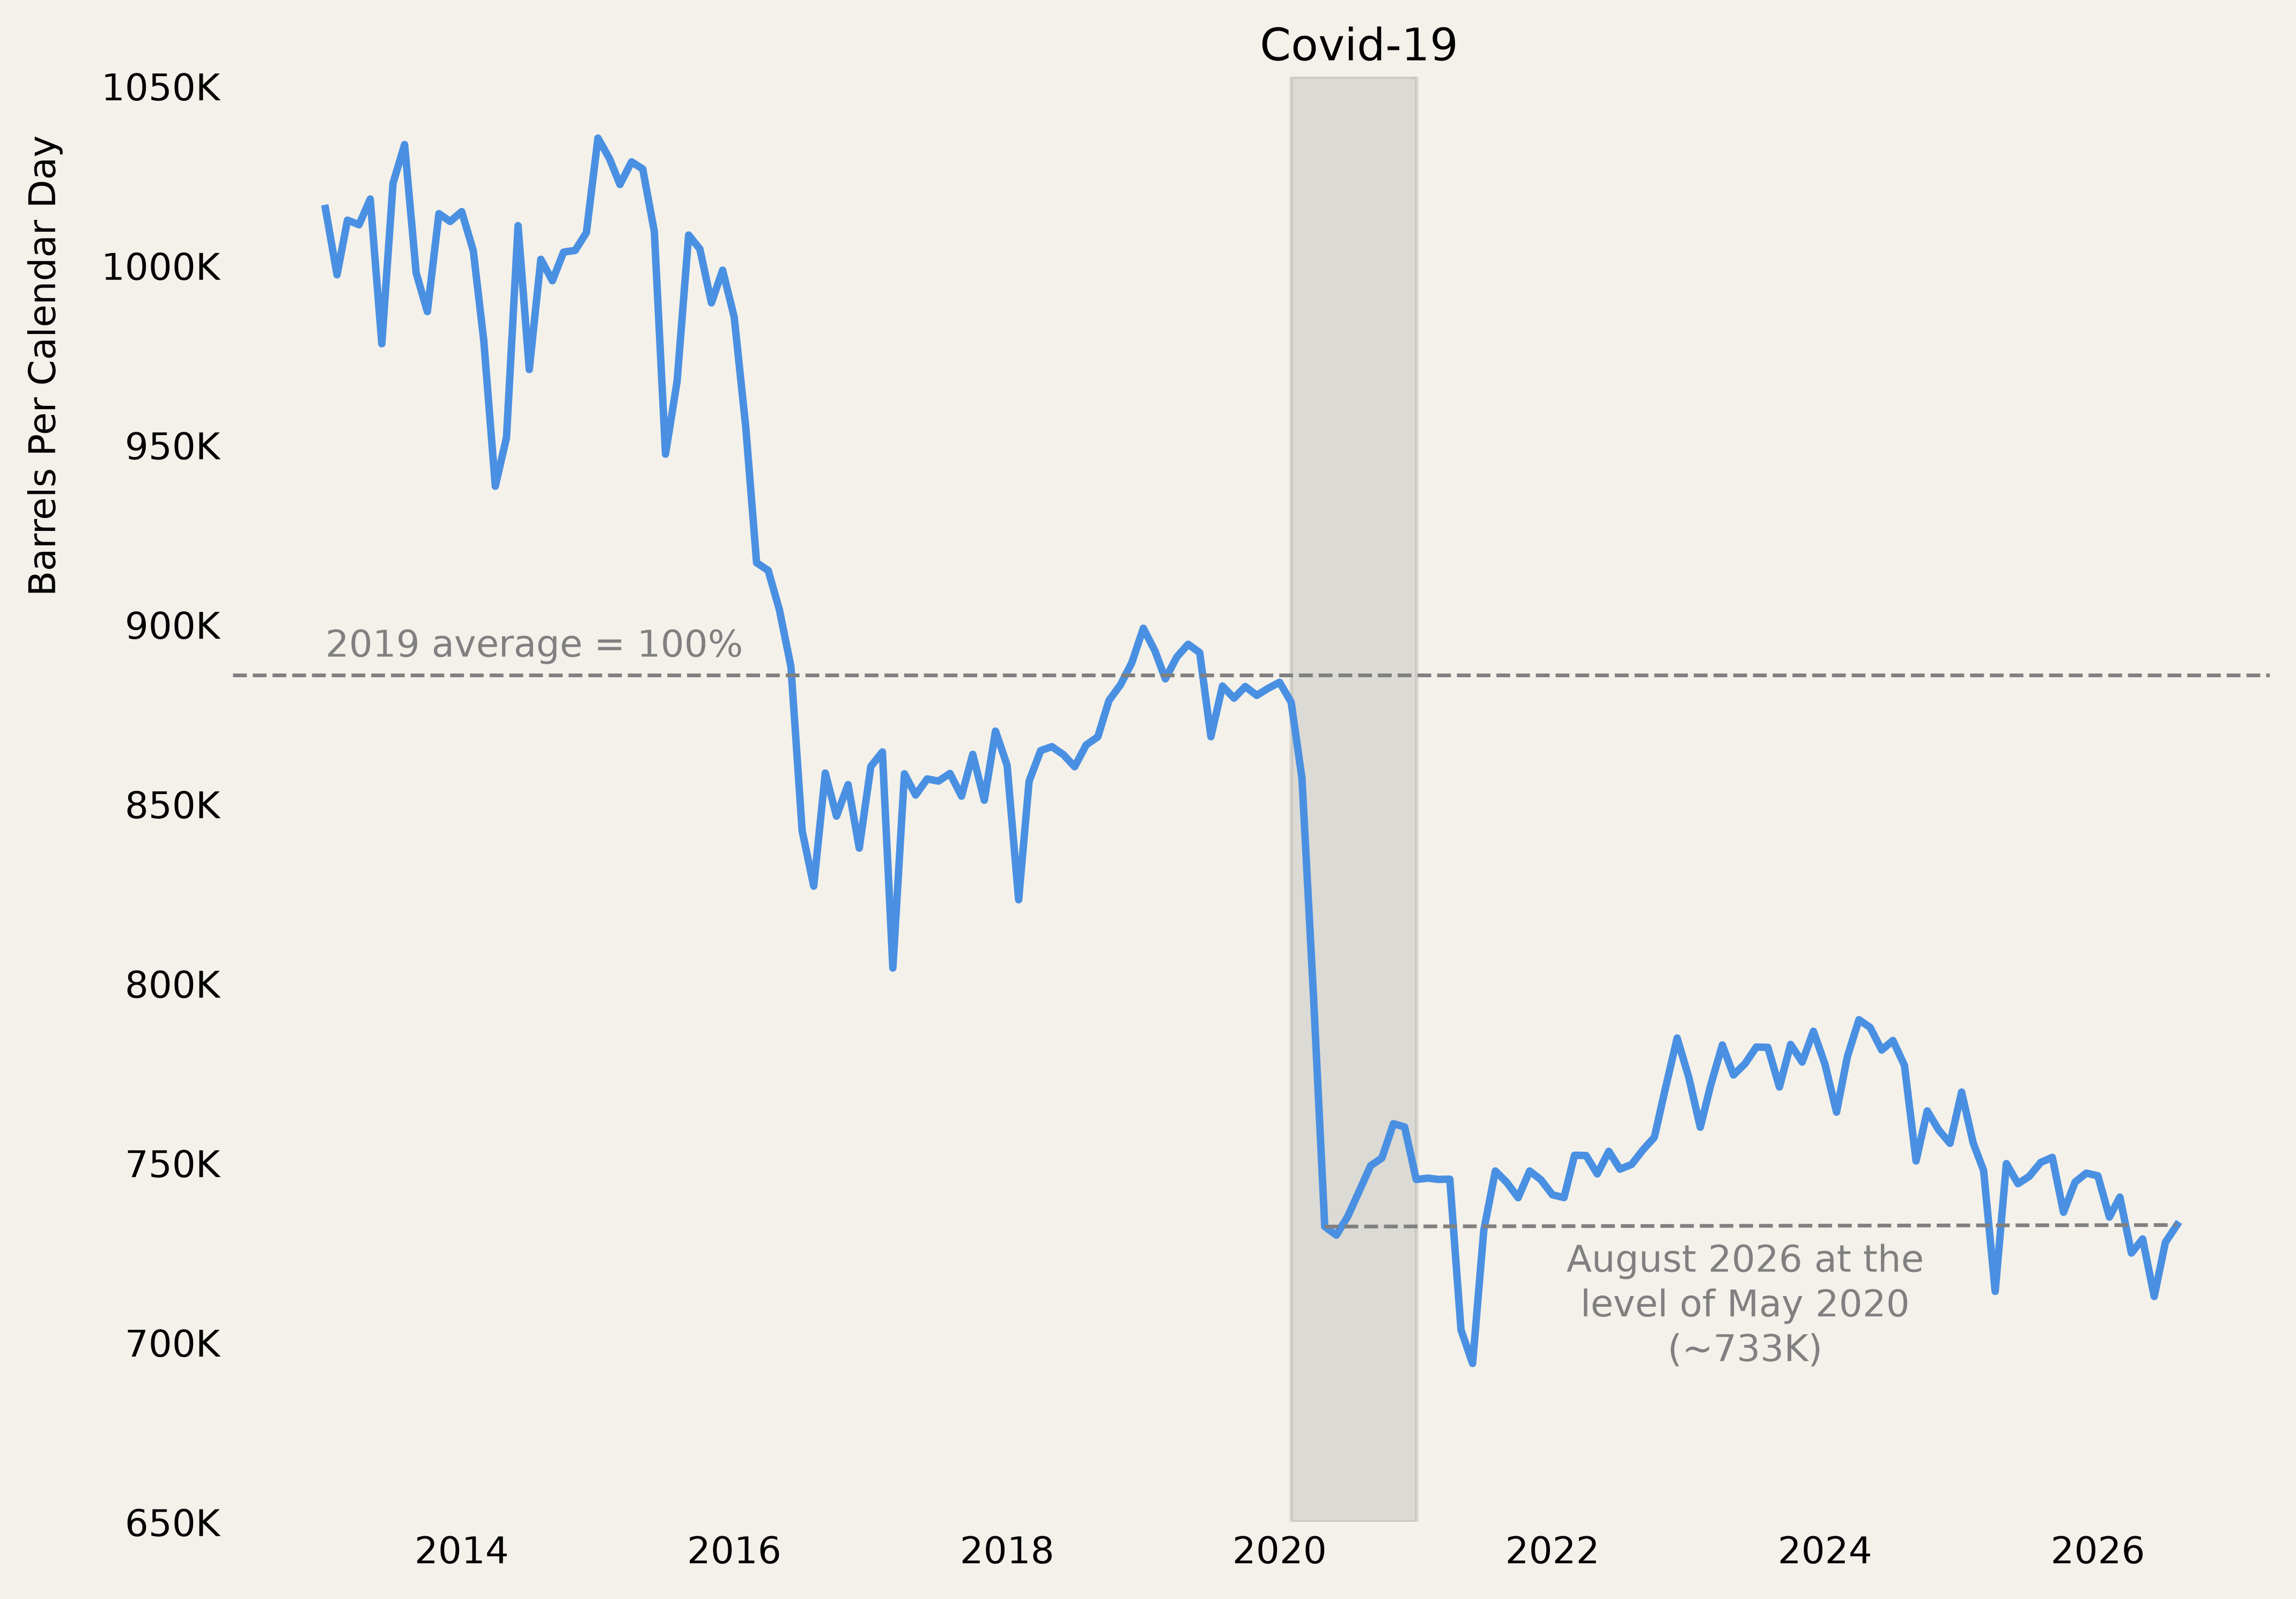

In [42]:
background = "#F4F1EA"
blue = "#4a90e2"
gray = "#808080"

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

plt.plot(df["date"], df["total_bpdc"], linewidth=2, color=blue)

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x/1000)}K"))

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Barrels Per Calendar Day", fontsize=10, labelpad=10, y=0.8)

plt.axvspan("2020-02", "2021", color=gray, alpha=0.2)

plt.ylim(650000)

plt.annotate(
    "Covid-19",
    xy=(pd.Timestamp("2020-08-01"), max["total_bpdc"]),
    xytext=(0, 30),
    textcoords="offset points",
    ha="center",
    va="top",
    fontsize=12
)

plt.axhline(avg_2019, color=gray, linestyle="--", linewidth=1)
plt.annotate(
    "2019 average = 100%",
    xy=(df["date"].iloc[0], avg_2019),
    xytext=(0, 5),
    textcoords="offset points",
    fontsize=10,
    color=gray
)

plt.plot(
    [trough["date"], last["date"]],
    [trough["total_bpdc"], last["total_bpdc"]],
    color=gray,
    linestyle="--",
    linewidth=1
)

plt.annotate(
    f"August 2026 at the\nlevel of May 2020\n(~{(df["total_bpdc"].iloc[-1] / 1000):.0f}K)",
    xy=(pd.Timestamp("2023-06-01"), 700000),
    xytext=(0, -5),
    textcoords="offset points",
    fontsize=10,
    color=gray,
    ha="center"
)

plt.show()